
🔵 CONSTANT ORACLE


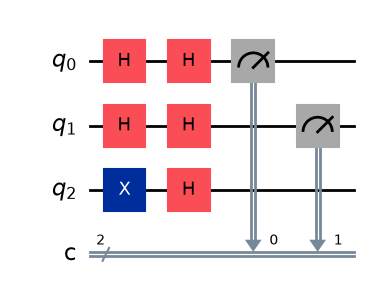

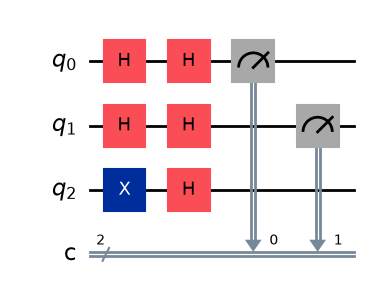

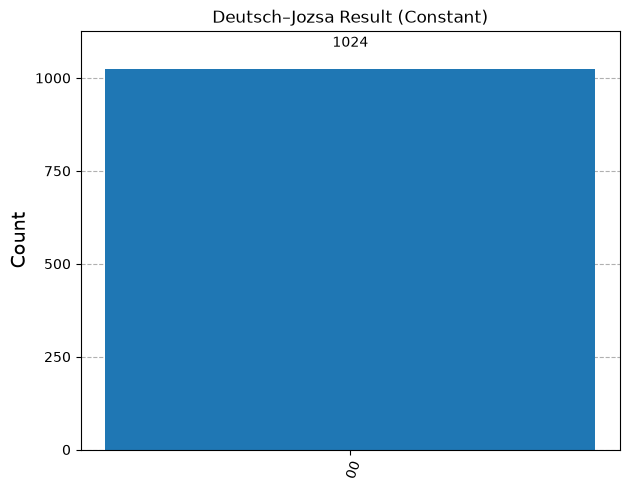

Counts: {'00': 1024}
Result: Function is CONSTANT

🟢 BALANCED ORACLE


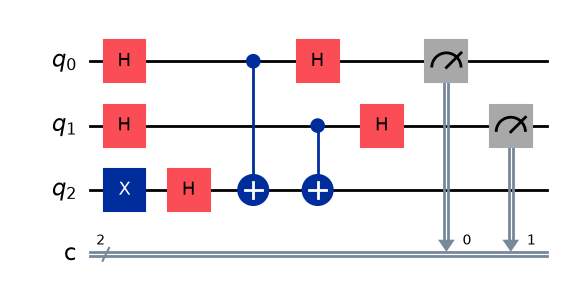

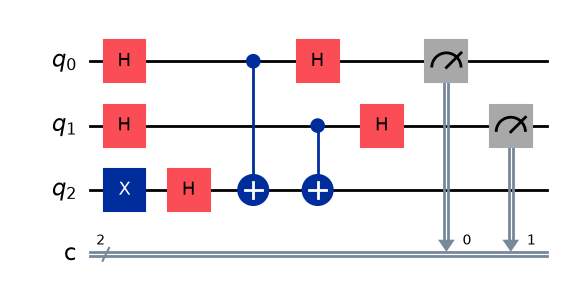

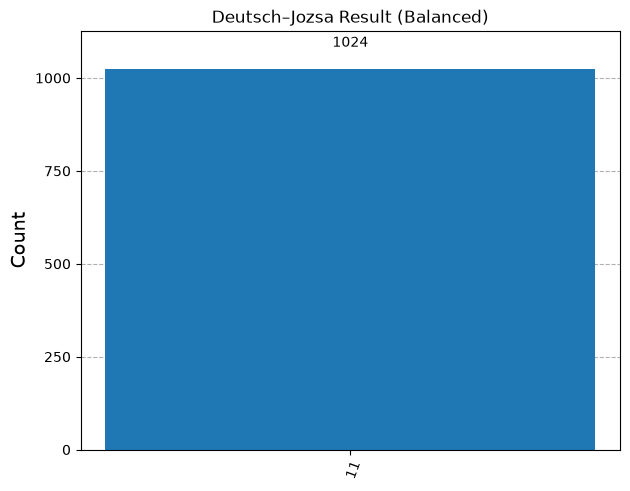

Counts: {'11': 1024}
Result: Function is BALANCED


In [1]:
# ======================================================
# FULL DEUTSCH–JOZSA LAB (Working Version)
# Uses modern qiskit-aer import
# ======================================================

%matplotlib inline

from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator   # ✅ Correct import
from qiskit.visualization import plot_histogram
from matplotlib import pyplot as plt
from IPython.display import display


# ------------------------------------------------------
# Function to Build Deutsch–Jozsa Circuit
# ------------------------------------------------------
def deutsch_jozsa_circuit(oracle_type="balanced"):
    
    n = 2
    qc = QuantumCircuit(n+1, n)
    
    # 1️⃣ Prepare ancilla in |1>
    qc.x(n)
    qc.h(n)
    
    # 2️⃣ Create superposition
    for qubit in range(n):
        qc.h(qubit)
    
    # 3️⃣ Oracle
    if oracle_type == "constant":
        pass  # f(x)=0
    
    elif oracle_type == "balanced":
        qc.cx(0, n)
        qc.cx(1, n)
    
    # 4️⃣ Interference
    for qubit in range(n):
        qc.h(qubit)
    
    # 5️⃣ Measurement
    for qubit in range(n):
        qc.measure(qubit, qubit)
    
    return qc


# ======================================================
# RUN CONSTANT CASE
# ======================================================
print("\n🔵 CONSTANT ORACLE")

qc_constant = deutsch_jozsa_circuit("constant")
display(qc_constant.draw("mpl"))

simulator = AerSimulator()
result = simulator.run(qc_constant, shots=1024).result()
counts_constant = result.get_counts()

plot_histogram(counts_constant)
plt.title("Deutsch–Jozsa Result (Constant)")
plt.show()

print("Counts:", counts_constant)

if list(counts_constant.keys())[0] == "00":
    print("Result: Function is CONSTANT")


# ======================================================
# RUN BALANCED CASE
# ======================================================
print("\n🟢 BALANCED ORACLE")

qc_balanced = deutsch_jozsa_circuit("balanced")
display(qc_balanced.draw("mpl"))

result = simulator.run(qc_balanced, shots=1024).result()
counts_balanced = result.get_counts()

plot_histogram(counts_balanced)
plt.title("Deutsch–Jozsa Result (Balanced)")
plt.show()

print("Counts:", counts_balanced)

if list(counts_balanced.keys())[0] != "00":
    print("Result: Function is BALANCED")
